In [2]:
%pip install pandas numpy matplotlib seaborn sickit-learn sqlalchemy pymysql python-dotenv

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sickit-learn (from versions: none)

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iarin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for sickit-learn


In [3]:
%pip install dotenv

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iarin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [4]:
%pip install sqlalchemy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iarin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
%pip install pymysql

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iarin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
import os
from dotenv import load_dotenv, find_dotenv
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote, quote_plus

# Load environment variables
load_dotenv(find_dotenv())

user = os.getenv("DB_USER")
password = quote_plus(os.getenv("DB_PASSWORD"))
host = os.getenv("DB_HOST")
port = os.getenv("DB_PORT")
database = os.getenv("DB_NAME")

# Connect to MySQL database
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}")

#Read the analysis view into a dataframe
df = pd.read_sql("SELECT * FROM vw_customer_analysis", engine)
df.shape

(7043, 54)

In [7]:
%pip install matplotlib
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iarin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\iarin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


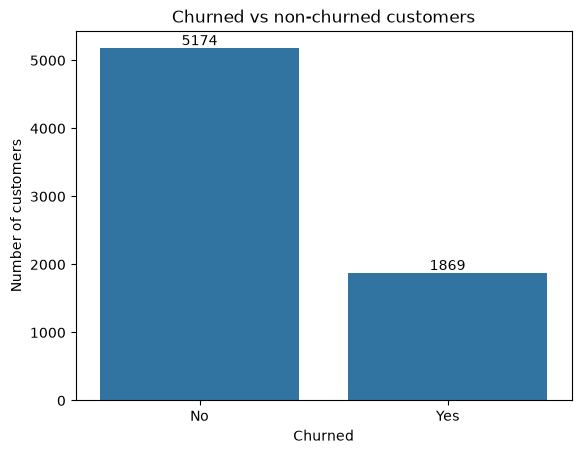

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the number of churned vs non-churned customers
ax = sns.countplot(data=df, x="churn_label", order=["No", "Yes"])

# Show the exact number on top of each bar
ax.bar_label(ax.containers[0])

ax.set_title("Churned vs non-churned customers")
ax.set_xlabel("Churned")
ax.set_ylabel("Number of customers")
plt.show()


#### Among all customers, only 1869 churn, which is two times less than the number of customers who stayed

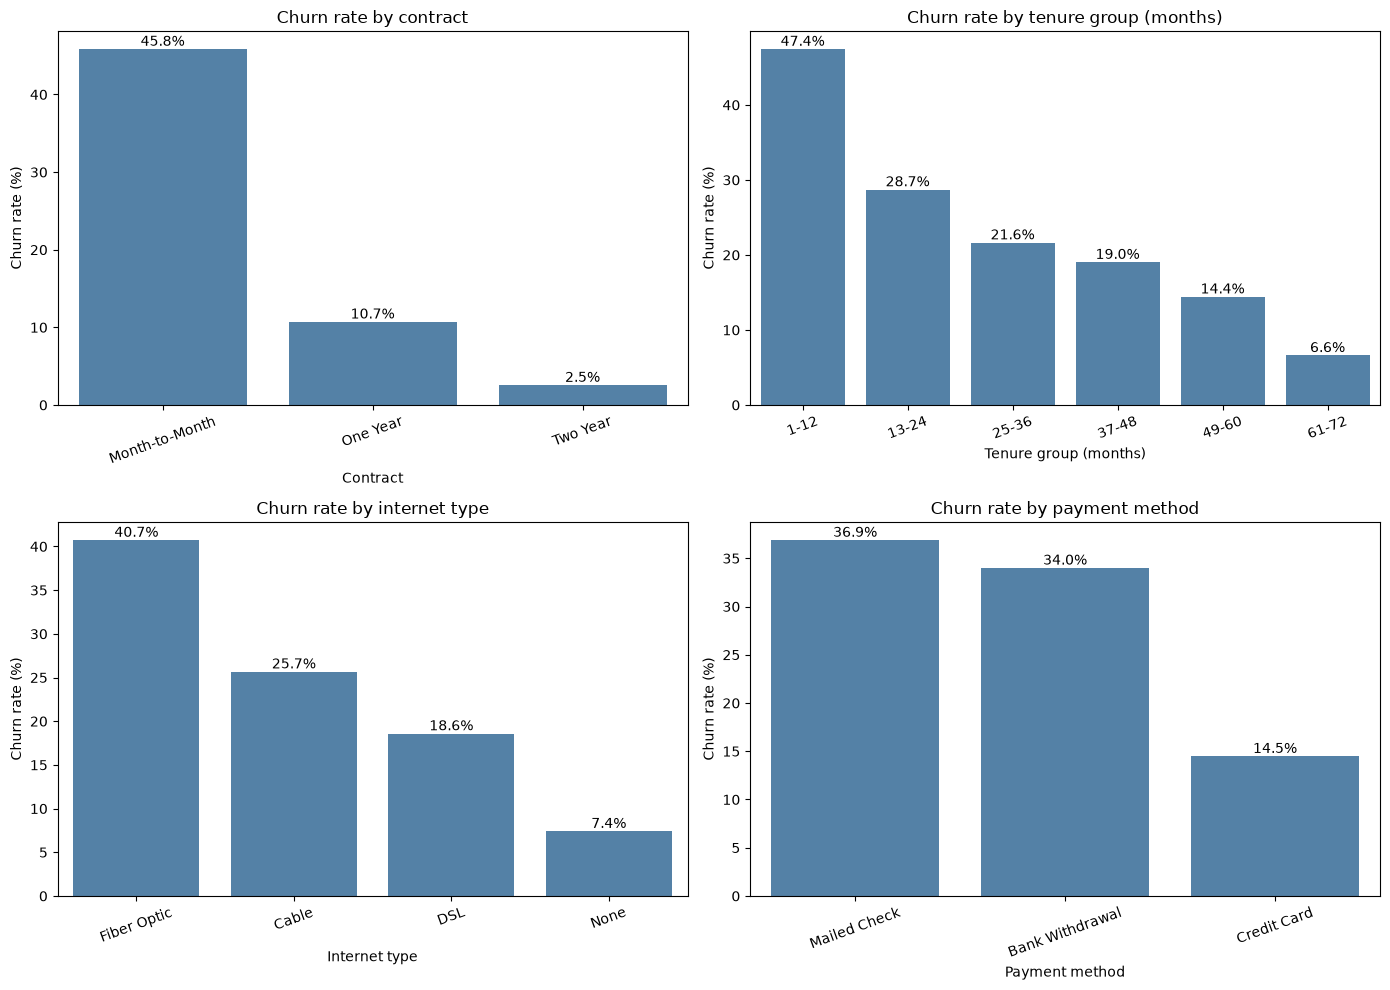

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Customers without internet have no internet type
df["internet_type"] = df["internet_type"].fillna("No internet")

# Column to plot -> chart title
segments = {
    "contract": "Contract",
    "tenure_group": "Tenure group (months)",
    "internet_type": "Internet type",
    "payment_method": "Payment method",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (col, title) in zip(axes.flat, segments.items()):
    # Churn rate (%) per category
    rates = df.groupby(col)["churn_value"].mean().mul(100)

    # Tenure groups keep their natural order; the rest go from highest to lowest churn
    if col == "tenure_group":
        order = df.sort_values("tenure_group_order")["tenure_group"].unique()
        rates = rates.reindex(order)
    else:
        rates = rates.sort_values(ascending=False)

    sns.barplot(x=rates.index, y=rates.values, ax=ax, color="steelblue")
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.set_title(f"Churn rate by {title.lower()}")
    ax.set_xlabel(title)
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


#### Churn is more likely among customers with month-to-month contracts; almost 50% of those customers churn 
#### First year customers churn the most => churn should be monitored for recent customers, as it becomes less likely as time passes
#### Customers with fiber optic churn the most
#### Customers who pay by credit card are way less likely to churn than those who pay by mailed check or bank withdrawal

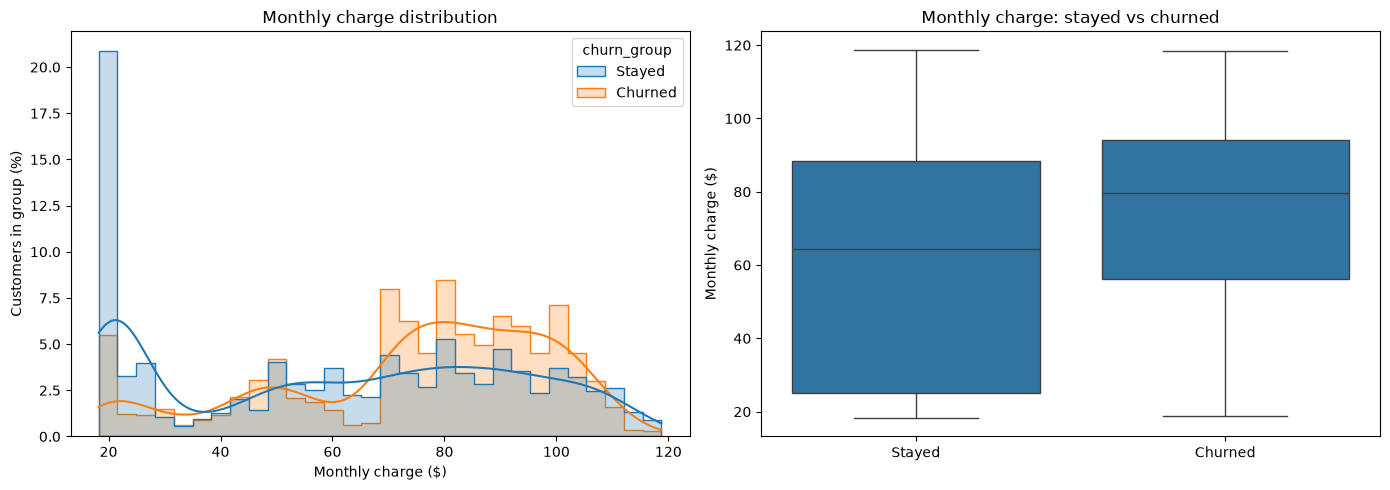

,count,mean,std,min,25%,50%,75%,max
churn_group,,,,,,,,
Stayed,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Churned,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Readable labels for the two groups
df["churn_group"] = df["churn_label"].map({"Yes": "Churned", "No": "Stayed"})
order = ["Stayed", "Churned"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution: each group scaled to 100% so the shapes are comparable
sns.histplot(
    data=df, x="monthly_charge", hue="churn_group", hue_order=order,
    bins=30, stat="percent", common_norm=False, kde=True,
    element="step", ax=axes[0],
)
axes[0].set_title("Monthly charge distribution")
axes[0].set_xlabel("Monthly charge ($)")
axes[0].set_ylabel("Customers in group (%)")

# Boxplot: median and spread for each group
sns.boxplot(data=df, x="churn_group", y="monthly_charge", order=order, ax=axes[1])
axes[1].set_title("Monthly charge: stayed vs churned")
axes[1].set_xlabel("")
axes[1].set_ylabel("Monthly charge ($)")

plt.tight_layout()
plt.show()

# Summary numbers for each group
df.groupby("churn_group")["monthly_charge"].describe().loc[order].round(2)


#### Around 21% of customers who stay pay ~ 20$
#### Customers who pay less than 40$ per month don't tend to churn
#### Customers who churn are usually those who pay between 70-105$
#### Customers who churn pay more per month than those who stay
#### The median monthly charge is around 80$ for churned customers, compared to around 64$ for those who stayed



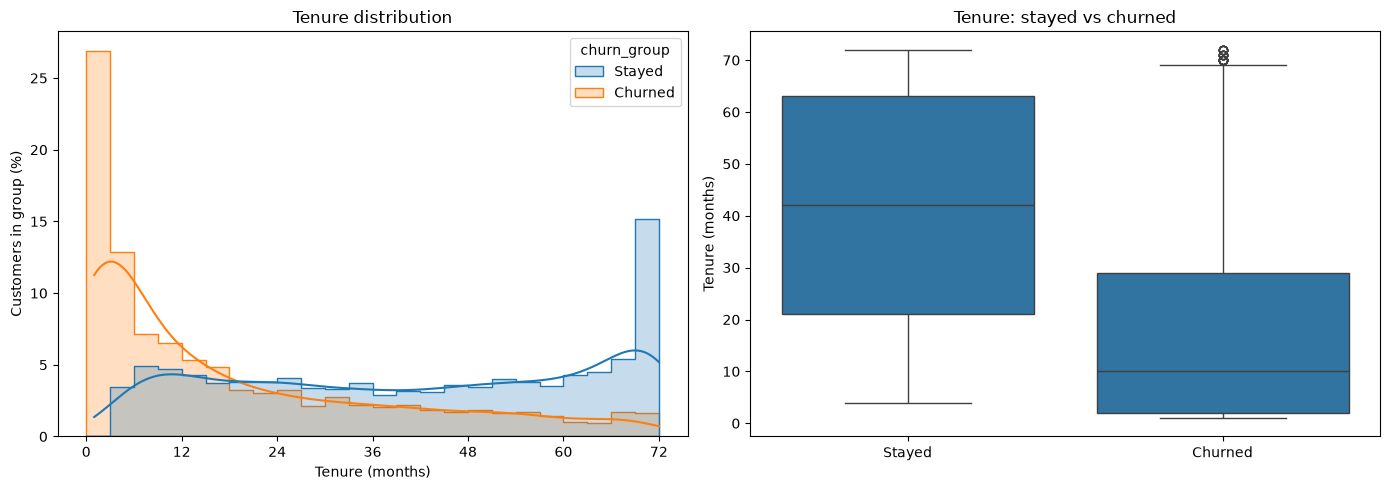

,count,mean,std,min,25%,50%,75%,max
churn_group,,,,,,,,
Stayed,4720.0,41.0,22.4,4.0,21.0,42.0,63.0,72.0
Churned,1869.0,18.0,19.5,1.0,2.0,10.0,29.0,72.0


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare only customers who stayed or churned (new "Joined" customers have very short tenure)
df_cmp = df[df["customer_status"] != "Joined"].copy()
df_cmp["churn_group"] = df_cmp["churn_label"].map({"Yes": "Churned", "No": "Stayed"})
order = ["Stayed", "Churned"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution: 3-month bins, each group scaled to 100%
sns.histplot(
    data=df_cmp, x="tenure_months", hue="churn_group", hue_order=order,
    binwidth=3, binrange=(0, 72), stat="percent", common_norm=False,
    kde=True, element="step", ax=axes[0],
)
axes[0].set_title("Tenure distribution")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Customers in group (%)")
axes[0].set_xticks(range(0, 73, 12))

# Boxplot: median and spread for each group
sns.boxplot(data=df_cmp, x="churn_group", y="tenure_months", order=order, ax=axes[1])
axes[1].set_title("Tenure: stayed vs churned")
axes[1].set_xlabel("")
axes[1].set_ylabel("Tenure (months)")

plt.tight_layout()
plt.show()

# Summary numbers for each group
df_cmp.groupby("churn_group")["tenure_months"].describe().loc[order].round(1)


#### Most customers churn in the first months, around 27% of them leaving in the first 3 months
#### After the first year, customers tend to churn less
#### Most loyal customers, around 15%, have been with the company for about 6 years
#### Half of churned customers who left have a tenure between 2 and 29 months
#### Half of the customers who stayed have a tenure between 21 and 63 months
#### Outliers show that there are a few customers who left after almost 6 years (Check for reasons of churn)

Long-tenure churned customers: 23 (1.2% of all churned customers)


,customer_id,tenure_months,contract,monthly_charge,internet_type,satisfaction_score,churn_category,churn_reason
665,0917-EZOLA,72,Two Year,104.15,Fiber Optic,3,Price,Extra data charges
2889,3886-CERTZ,72,One Year,109.25,Fiber Optic,1,Competitor,Competitor had better devices
5327,8580-QVLOC,72,Two Year,92.45,DSL,1,Competitor,Competitor made better offer
5705,2889-FPWRM,72,One Year,117.80,Fiber Optic,2,Competitor,Competitor offered higher download speeds
6309,8809-RIHDD,72,Two Year,103.40,Fiber Optic,3,Price,Lack of affordable download/upload speed
6344,6034-ZRYCV,72,Two Year,54.20,Cable,3,Competitor,Competitor offered more data
5812,2530-ENDWQ,71,Two Year,93.70,Fiber Optic,3,Competitor,Competitor offered more data
6241,3259-FDWOY,71,Two Year,106.00,Fiber Optic,3,Competitor,Competitor offered higher download speeds
6023,7317-GGVPB,71,Two Year,108.60,Fiber Optic,1,Dissatisfaction,Product dissatisfaction
4393,2834-JRTUA,71,Two Year,108.05,Fiber Optic,1,Competitor,Competitor had better devices


,customers,share
churn_category,,
Competitor,9,39.1
Price,5,21.7
Dissatisfaction,5,21.7
Attitude,4,17.4


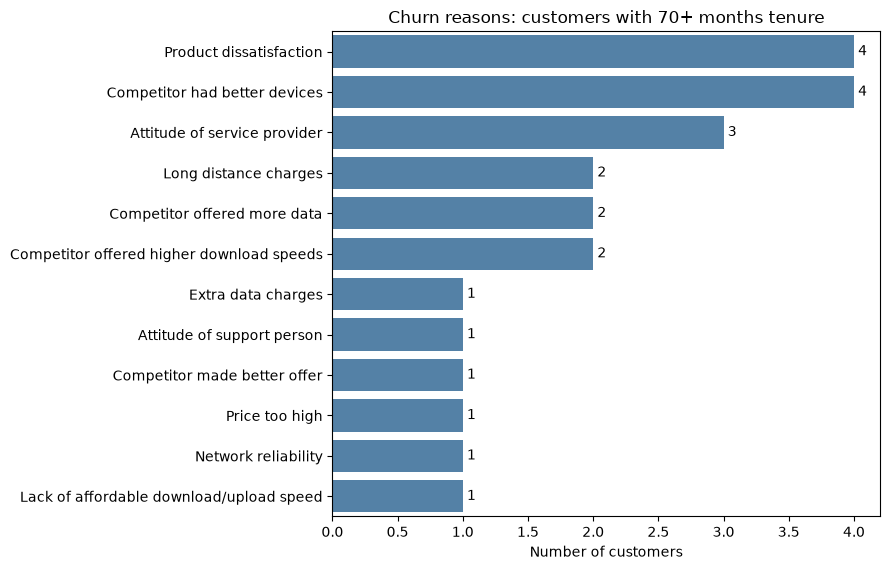

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Churned customers with 70+ months of tenure
long_churned = df[(df["churn_value"] == 1) & (df["tenure_months"] >= 70)]

total_churned = (df["churn_value"] == 1).sum()
print(f"Long-tenure churned customers: {len(long_churned)} "
      f"({len(long_churned) / total_churned:.1%} of all churned customers)")

# A quick look at who they are
cols = ["customer_id", "tenure_months", "contract", "monthly_charge",
        "internet_type", "satisfaction_score", "churn_category", "churn_reason"]
display(long_churned[cols].sort_values("tenure_months", ascending=False).head(20))

# Churn categories (broad groups)
display(
    long_churned["churn_category"].value_counts()
    .to_frame("customers")
    .assign(share=lambda t: (t["customers"] / t["customers"].sum() * 100).round(1))
)

# Detailed churn reasons
reasons = long_churned["churn_reason"].value_counts()

fig, ax = plt.subplots(figsize=(9, len(reasons) * 0.4 + 1))
sns.barplot(x=reasons.values, y=reasons.index, ax=ax, color="steelblue")
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Churn reasons: customers with 70+ months tenure")
ax.set_xlabel("Number of customers")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


#### Among the customers with a tenure of more than 70 months, 4 left due to product dissatisfaction, and 4 others due to competitors having better offers.
#### Most leave because of better offers from competitors.

### The code below is intended for converting yes/no columns to 1/0 on a copy (df_encoded), keeping original values intact (df)

In [19]:
df_encoded = df.copy()

# Find columns whose only values are "Yes" and "No"
yes_no_cols = [
    col for col in df_encoded.columns
    if (pd.api.types.is_object_dtype(df_encoded[col]) or pd.api.types.is_string_dtype(df_encoded[col]))
    and set(df_encoded[col].dropna().unique()) <= {"Yes", "No"}
]

# Yes -> 1, No -> 0
df_encoded[yes_no_cols] = (
    df_encoded[yes_no_cols]
    .apply(lambda col: col.map({"Yes": 1, "No": 0}))
    .astype(int)
)

# churn_label is now identical to churn_value, so drop it
df_encoded = df_encoded.drop(columns="churn_label")

print(f"Converted {len(yes_no_cols)} columns:", yes_no_cols)
df_encoded.head()

Converted 18 columns: ['under_30', 'senior_citizen', 'married', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection_plan', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'unlimited_data', 'paperless_billing', 'referred_friend', 'churn_label']


,customer_id,gender,age,under_30,senior_citizen,married,dependents,number_of_dependents,zip_code,city,...,total_revenue,customer_status,is_existing_customer,churn_value,churn_score,satisfaction_score,cltv,churn_category,churn_reason,churn_group
0,0136-IFMYD,Male,71,0,1,1,0,0,90001,Los Angeles,...,8904.54,Stayed,1,0,63,5,4297,NaN,NaN,Stayed
1,3217-FZDMN,Female,66,0,1,0,0,0,90001,Los Angeles,...,784.63,Churned,1,1,83,1,3676,Competitor,Competitor had better devices,Churned
2,3307-TLCUD,Male,36,0,0,1,0,0,90001,Los Angeles,...,592.75,Stayed,1,0,45,3,4207,NaN,NaN,Stayed
3,7590-VHVEG,Female,36,0,0,1,0,0,90001,Los Angeles,...,29.85,Joined,0,0,27,3,3964,NaN,NaN,Stayed
4,4486-EFAEB,Male,56,0,0,0,0,0,90002,Los Angeles,...,861.61,Stayed,1,0,54,5,2486,NaN,NaN,Stayed


In [18]:
df["married"].dtype

<StringDtype(storage='python', na_value=nan)>

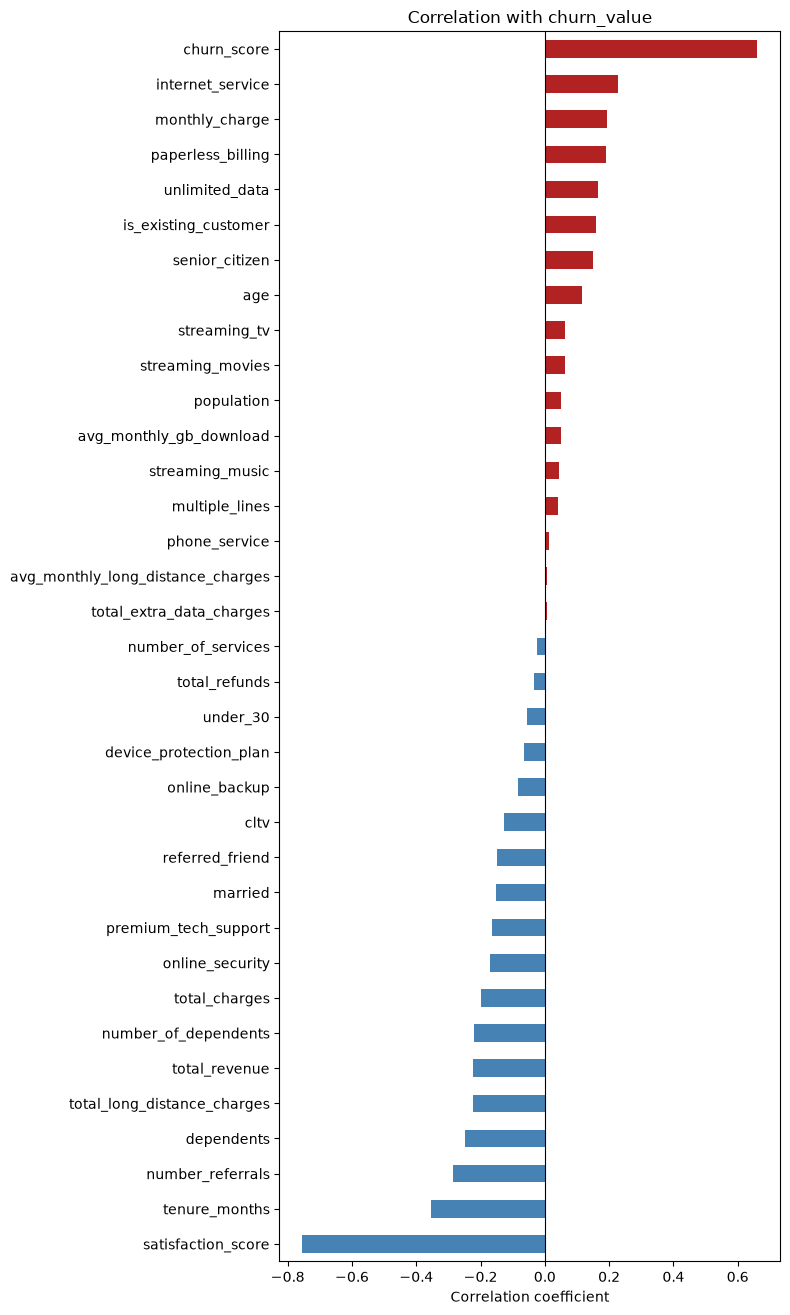

,corr_with_churn
satisfaction_score,-0.755
churn_score,0.661
tenure_months,-0.353
number_referrals,-0.287
dependents,-0.249
internet_service,0.228
total_long_distance_charges,-0.224
total_revenue,-0.223
number_of_dependents,-0.219
total_charges,-0.199


In [20]:
import matplotlib.pyplot as plt

# Columns that are not real features (IDs, coordinates, sort helpers, duplicates of churn)
exclude = [
    "churn_value", "churn_label",
    "zip_code", "latitude", "longitude",
    "tenure_group_order", "monthly_charge_group_order",
]

numeric = df_encoded.select_dtypes("number").drop(columns=exclude, errors="ignore")

# Correlation of each numeric column with churn_value, strongest first
corr = (
    numeric.astype("float")
    .corrwith(df_encoded["churn_value"])
    .dropna()
    .sort_values(key=abs, ascending=False)
)

# Bar chart: red = linked to more churn, blue = linked to less churn
fig, ax = plt.subplots(figsize=(8, len(corr) * 0.35 + 1))
corr.sort_values().plot.barh(
    ax=ax, color=["firebrick" if v > 0 else "steelblue" for v in corr.sort_values()]
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation with churn_value")
ax.set_xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

corr.round(3).to_frame("corr_with_churn")


#### Tenure is the strongest factor, the longer a customer stayes, the less likely they are to churn
#### Referrals, dependents, online security and tech support are linked to lower churn
#### Internet service, higher monthly charges, paperless billing and older age are all linked to a higher churn rate
#### Contract, internet type, payment method and offer will be analyzed later on, due to them being text variables (can't be converted to binary)

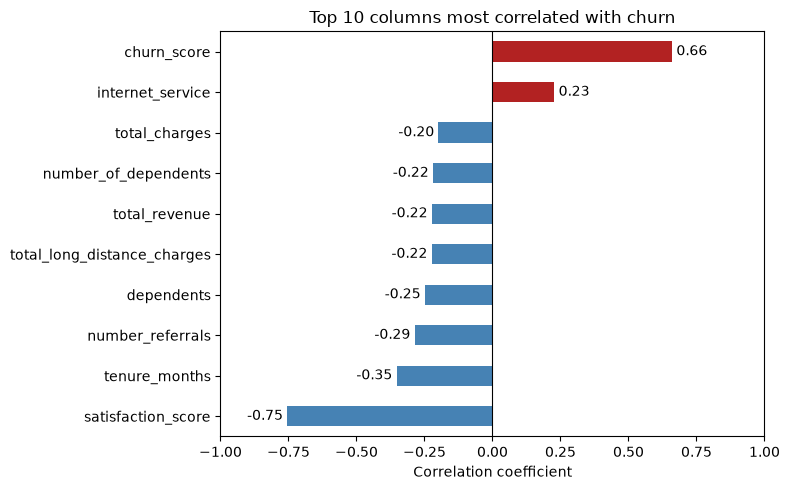

,corr_with_churn,direction
satisfaction_score,-0.755,less churn
churn_score,0.661,more churn
tenure_months,-0.353,less churn
number_referrals,-0.287,less churn
dependents,-0.249,less churn
internet_service,0.228,more churn
total_long_distance_charges,-0.224,less churn
total_revenue,-0.223,less churn
number_of_dependents,-0.219,less churn
total_charges,-0.199,less churn


In [21]:
import matplotlib.pyplot as plt

# Top 10 by strength of correlation (positive or negative)
top10 = corr.head(10)

# Bar chart: red = more churn, blue = less churn
top10_sorted = top10.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
top10_sorted.plot.barh(
    ax=ax, color=["firebrick" if v > 0 else "steelblue" for v in top10_sorted]
)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 10 columns most correlated with churn")
ax.set_xlabel("Correlation coefficient")
ax.set_xlim(-1, 1)
plt.tight_layout()
plt.show()

# Table with the direction spelled out
top10.round(3).to_frame("corr_with_churn").assign(
    direction=lambda t: t["corr_with_churn"].map(lambda v: "more churn" if v > 0 else "less churn")
)


#### Tenure, number of referrals and dependents are linked to lower churn rated
#### Internet service is the only applicable factor linked to higher churn
#### Total charges, total revenue and total long distance charges can't be taken into account since they are linked to churn only because they grow with tenure

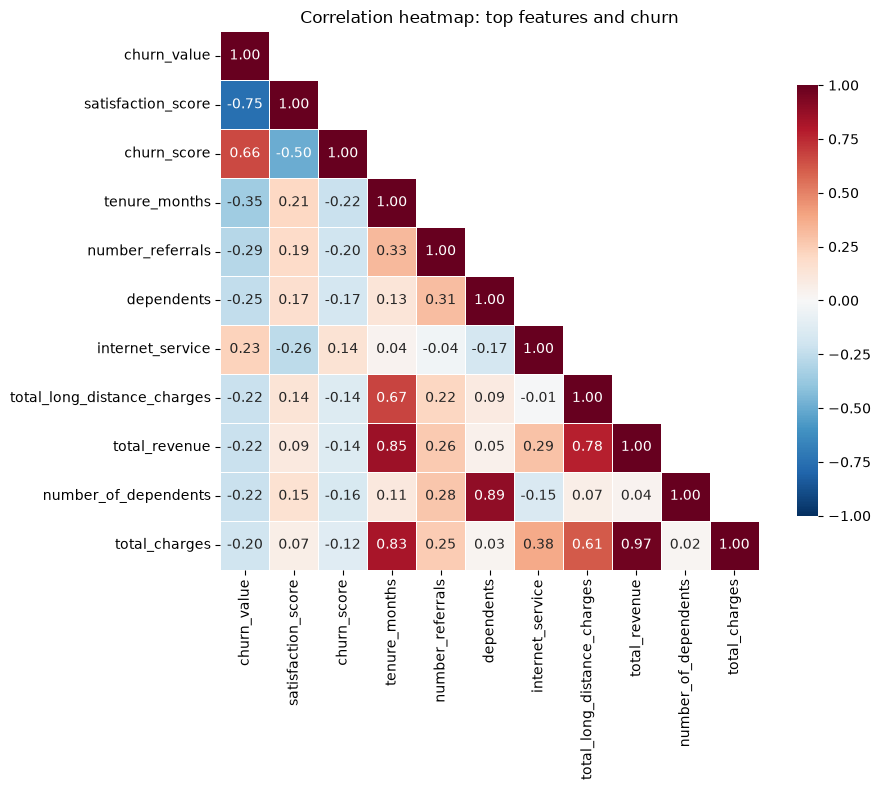

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Top 10 columns from the previous step + the target
cols = ["churn_value"] + list(top10.index)
corr_matrix = df_encoded[cols].astype("float").corr()

# Hide the upper half: it mirrors the lower half
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("Correlation heatmap: top features and churn")
plt.tight_layout()
plt.show()


#### Total revenue, total charges and total long distance charges are stronly correlated
#### Total revenue and total charges are almost identical
#### Dependents and number of dependents represent the same information
#### For the model, only one variable from each highly coorelated group will be kept to avoid multicoliniarity: tenure_months instead of totals and number_of_dependants instead of dependants